# Step 4 — LSTM and GRU
**Inputs needed (Add Input → Notebook Output):** Step 1 (`splits/`), Step 2 (`processed/`), and Step 3 (`results/` — optional, only to include TF-IDF and SimpleRNN in the final table).

**Why LSTM / GRU?** SimpleRNN keeps one hidden state that gets overwritten at every word, so information from early words fades (vanishing gradients). 
- **LSTM** adds a separate *cell state* with 3 gates (forget / input / output) that decide what to keep, write and expose.
- **GRU** is a lighter version with 2 gates (reset / update) and no separate cell state → fewer parameters, usually faster, often just as accurate.

To make the comparison fair we keep **everything identical** to SimpleRNN (same embedding, units, dropout, optimizer, class weights, callbacks, seed) and change **only the recurrent layer**.

## 4.1 Setup & load

In [6]:
import os, glob, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

SEED = 42
QUICK = False   # True = smoke test on a tiny subset

def find(pattern, required=True):
    hits = glob.glob(pattern) + glob.glob('/kaggle/input/**/' + pattern, recursive=True) + glob.glob('/kaggle/working/' + pattern)
    if required: assert hits, f'Could not find {pattern}. Add the previous steps\' notebook outputs as Input.'
    return hits[0] if hits else None

data = np.load(find('processed/data.npz'))
X_train, y_train, X_val, y_val, X_test, y_test = [data[k] for k in ['X_train','y_train','X_val','y_val','X_test','y_test']]
meta = json.load(open(find('processed/meta.json')))
tok  = json.load(open(find('processed/tokenizer.json')))
label2id = meta['label2id']; class_weight = {int(k): v for k, v in meta['class_weight'].items()}
class_names = [c for c, _ in sorted(label2id.items(), key=lambda x: x[1])]
VOCAB_SIZE, MAX_LEN = tok['vocab_size'], tok['max_len']

if QUICK:
    X_train, y_train = X_train[:3000], y_train[:3000]
    X_val, y_val = X_val[:1000], y_val[:1000]
    X_test, y_test = X_test[:1000], y_test[:1000]

os.makedirs('results', exist_ok=True); os.makedirs('models', exist_ok=True)
print(X_train.shape, X_val.shape, X_test.shape)
print('GPU:', tf.config.list_physical_devices('GPU'))

(86914, 250) (18625, 250) (18625, 250)
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 4.2 Same evaluation + plotting helpers as Step 3

In [9]:
def evaluate_model(name, y_true, y_pred, plot=True):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    print(f'===== {name} =====')
    print(f'Accuracy {acc:.4f} | Macro-Precision {p:.4f} | Macro-Recall {r:.4f} | Macro-F1 {f1:.4f}\n')
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    if plot:
        cmn = cm / cm.sum(axis=1, keepdims=True)
        fig, ax = plt.subplots(1, 2, figsize=(15, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax[0]); ax[0].set_title(f'{name} — counts')
        sns.heatmap(cmn, annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax[1]); ax[1].set_title(f'{name} — row-normalised (recall per class)')
        for a in ax: a.set_xlabel('Predicted'); a.set_ylabel('True'); a.tick_params(axis='x', rotation=30)
        plt.tight_layout(); plt.show()
    res = {'model': name, 'accuracy': acc, 'macro_precision': p, 'macro_recall': r, 'macro_f1': f1, 'confusion_matrix': cm.tolist()}
    json.dump(res, open(f'results/{name}.json', 'w'))
    return res

def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.history['loss'], label='train'); ax[0].plot(h.history['val_loss'], label='val'); ax[0].set_title(f'{title} — loss'); ax[0].legend()
    ax[1].plot(h.history['accuracy'], label='train'); ax[1].plot(h.history['val_accuracy'], label='val'); ax[1].set_title(f'{title} — accuracy'); ax[1].legend()
    plt.tight_layout(); plt.show()

## 4.3 One function that builds, trains and evaluates any recurrent model
Only `rnn_layer` changes between models. We reset the seed before each model so both start from the same conditions.

In [11]:
EMB_DIM, UNITS = 128, 64

def build_model(name, rnn_layer):
    m = keras.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, EMB_DIM),
        rnn_layer,
        layers.Dropout(0.3),
        layers.Dense(len(class_names), activation='softmax'),
    ], name=name)
    m.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

def train_and_eval(name, rnn_layer):
    keras.utils.set_random_seed(SEED)
    model = build_model(name.lower(), rnn_layer)
    model.summary()
    callbacks = [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, min_lr=1e-5),
    ]
    t0 = time.time()
    hist = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                     epochs=2 if QUICK else 15, batch_size=128,
                     class_weight=class_weight, callbacks=callbacks, verbose=2)
    minutes = (time.time() - t0) / 60
    print(f'Training time: {minutes:.1f} min')
    plot_history(hist, name)
    probs = model.predict(X_test, batch_size=256, verbose=0)
    res = evaluate_model(name, y_test, probs.argmax(1))
    res['train_minutes'] = minutes
    res['params'] = int(model.count_params())
    json.dump(res, open(f'results/{name}.json', 'w'))
    np.save(f'results/{name}_test_probs.npy', probs)
    model.save(f'models/{name.lower()}.keras')
    return res

## 4.4 LSTM

Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 250, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,609,733 (9.96 MB)

 Trainable params: 2,609,733 (9.96 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
680/680 - 13s - 19ms/step - accuracy: 0.7536 - loss: 0.7036 - val_accuracy: 0.8191 - val_loss: 0.5590 - learning_rate: 0.0010
Epoch 2/15
680/680 - 11s - 16ms/step - accuracy: 0.8274 - loss: 0.4903 - val_accuracy: 0.8274 - val_loss: 0.5082 - learning_rate: 0.0010
Epoch 3/15
680/680 - 11s - 16ms/step - accuracy: 0.8450 - loss: 0.4320 - val_accuracy: 0.8251 - val_loss: 0.5088 - learning_rate: 0.0010
Epoch 4/15
680/680 - 11s - 16ms/step - accuracy: 0.8651 - loss: 0.3662 - val_accuracy: 0.8301 - val_loss: 0.5018 - learning_rate: 5.0000e-04
Epoch 5/15
680/680 - 11s - 16ms/step - accuracy: 0.8763 - loss: 0.3317 - val_accuracy: 0.8325 - val_loss: 0.5015 - learning_rate: 5.0000e-04
Epoch 6/15
680/680 - 11s - 16ms/step - accuracy: 0.8841 - loss: 0.3081 - val_accuracy: 0.8313 - val_loss: 0.5174 - learning_rate: 5.0000e-04
Epoch 7/15
680/680 - 11s - 16ms/step - accuracy: 0.8942 - loss: 0.2778 - val_accuracy: 0.8320 - val_loss: 0.5257 - learning_rate: 2.5000e-04
Epoch 8/15
680/680 - 11s 

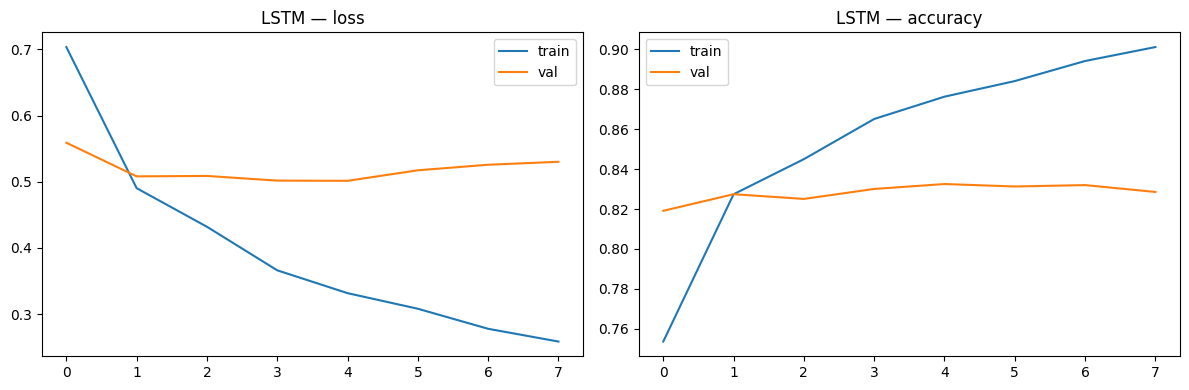

===== LSTM =====
Accuracy 0.8328 | Macro-Precision 0.8037 | Macro-Recall 0.8437 | Macro-F1 0.8213

                     precision    recall  f1-score   support

        credit_card      0.726     0.806     0.764      2245
   credit_reporting      0.930     0.811     0.866      8414
    debt_collection      0.747     0.829     0.786      3145
mortgages_and_loans      0.793     0.882     0.835      2804
     retail_banking      0.822     0.890     0.855      2017

           accuracy                          0.833     18625
          macro avg      0.804     0.844     0.821     18625
       weighted avg      0.842     0.833     0.835     18625



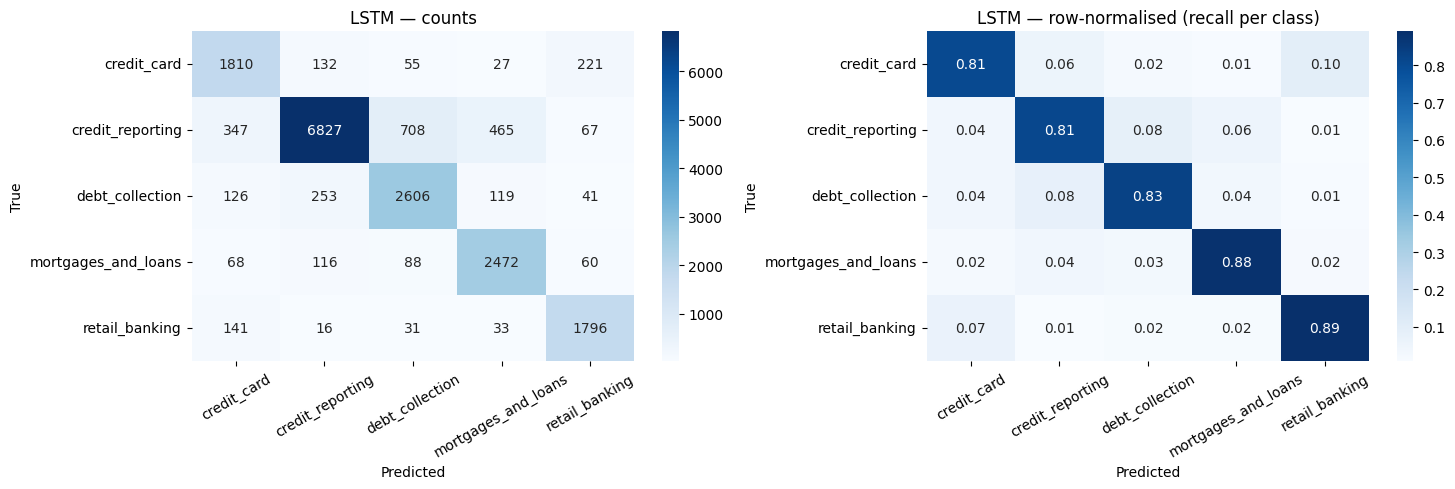

In [12]:
res_lstm = train_and_eval('LSTM', layers.LSTM(UNITS))

## 4.5 GRU

Model: "gru"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 250, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,597,573 (9.91 MB)

 Trainable params: 2,597,573 (9.91 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
680/680 - 12s - 18ms/step - accuracy: 0.7477 - loss: 0.7023 - val_accuracy: 0.8348 - val_loss: 0.4628 - learning_rate: 0.0010
Epoch 2/15
680/680 - 10s - 15ms/step - accuracy: 0.8434 - loss: 0.4242 - val_accuracy: 0.8414 - val_loss: 0.4544 - learning_rate: 0.0010
Epoch 3/15
680/680 - 10s - 15ms/step - accuracy: 0.8622 - loss: 0.3679 - val_accuracy: 0.8381 - val_loss: 0.4716 - learning_rate: 0.0010
Epoch 4/15
680/680 - 10s - 15ms/step - accuracy: 0.8816 - loss: 0.3080 - val_accuracy: 0.8372 - val_loss: 0.4944 - learning_rate: 5.0000e-04
Epoch 5/15
680/680 - 10s - 15ms/step - accuracy: 0.8940 - loss: 0.2697 - val_accuracy: 0.8361 - val_loss: 0.4984 - learning_rate: 2.5000e-04
Training time: 0.9 min


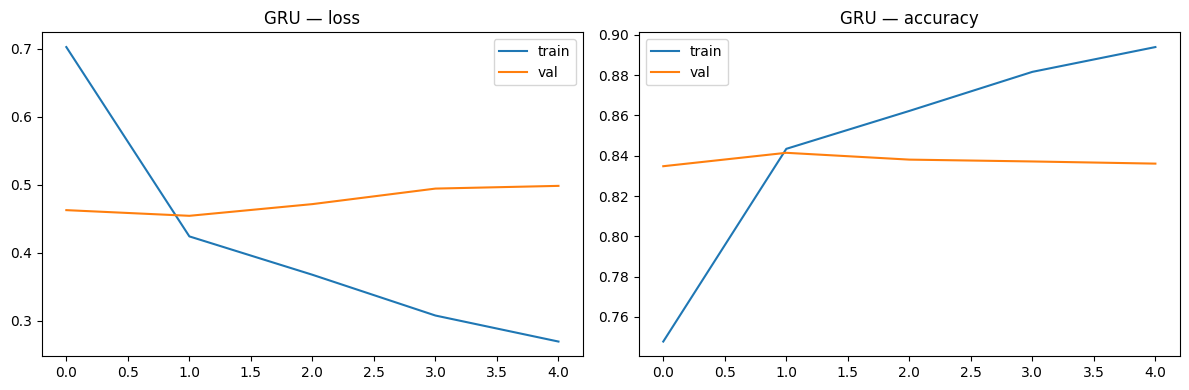

===== GRU =====
Accuracy 0.8452 | Macro-Precision 0.8237 | Macro-Recall 0.8476 | Macro-F1 0.8338

                     precision    recall  f1-score   support

        credit_card      0.759     0.816     0.787      2245
   credit_reporting      0.920     0.840     0.878      8414
    debt_collection      0.785     0.811     0.798      3145
mortgages_and_loans      0.772     0.913     0.837      2804
     retail_banking      0.883     0.857     0.870      2017

           accuracy                          0.845     18625
          macro avg      0.824     0.848     0.834     18625
       weighted avg      0.851     0.845     0.846     18625



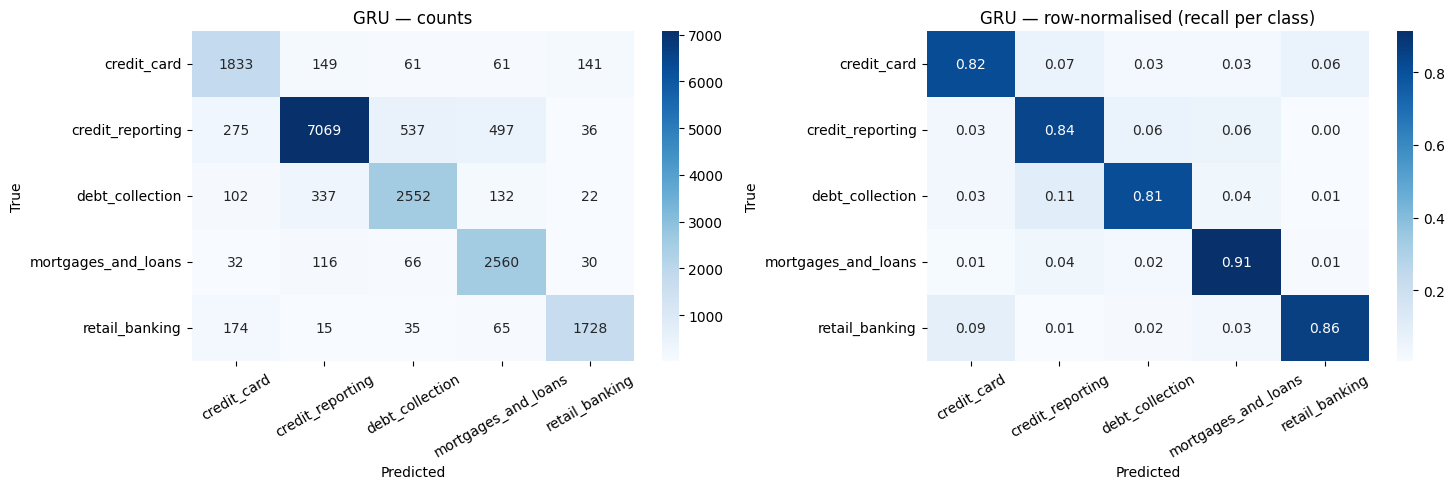

In [13]:
res_gru = train_and_eval('GRU', layers.GRU(UNITS))

## 4.6 Comparison table
Includes TF-IDF and SimpleRNN from Step 3 if its `results/` folder was added as input.

,model,accuracy,macro_precision,macro_recall,macro_F1,train_min,params
0,TFIDF_LogReg,0.8628,0.8401,0.8629,0.8507,NaN,NaN
1,SimpleRNN,0.8154,0.7843,0.8101,0.7962,2.7883,NaN
2,LSTM,0.8328,0.8037,0.8437,0.8213,1.4996,2609733.0
3,GRU,0.8452,0.8237,0.8476,0.8338,0.8936,2597573.0


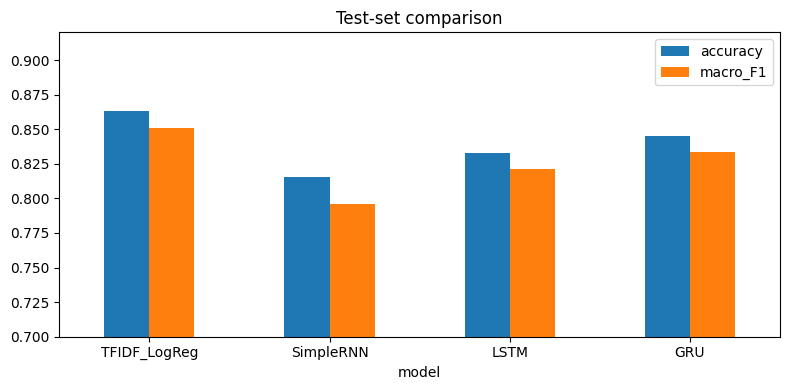

In [14]:
rows = []
for n in ['TFIDF_LogReg', 'SimpleRNN']:
    p = find(f'results/{n}.json', required=False)
    if p: rows.append(json.load(open(p)))
rows += [res_lstm, res_gru]

comp = pd.DataFrame([{'model': r['model'], 'accuracy': r['accuracy'], 'macro_precision': r['macro_precision'],
                      'macro_recall': r['macro_recall'], 'macro_F1': r['macro_f1'],
                      'train_min': r.get('train_minutes'), 'params': r.get('params')} for r in rows]).round(4)
display(comp)

ax = comp.set_index('model')[['accuracy', 'macro_F1']].plot.bar(figsize=(8, 4), ylim=(0.7, 0.92), rot=0)
ax.set_title('Test-set comparison'); plt.tight_layout(); plt.show()